### CNN Model

The CNN model is built for the orginal data sets and data created by DCGAN. The model is trained on the mixed data of orginal and data from DCGAN and found the best hyper parameters. The test data is predited by the final model and evaluated.

## Useful Libraries


- PyTorch: Building and training the CNN model
- scikit-learn: Measure the model’s predictive performance.
- os: Handles folder paths.
- glob: finds files matching
- shutil: copies/moves files.
- random: random sampling, shuffling.
- pandas: Used to read and organizing data
- matplotlib & seaborn: Visualizaing data
- numpy: Mathematical operations

In [33]:
import os, glob, shutil, random, pandas as pd
from sklearn.model_selection import train_test_split
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np
from torchvision import transforms, datasets, utils, models
from torch.utils.data import DataLoader
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

## Preparing Data

- Preparing the orginal and synthetic data
- Splitting the data into train, val and test with the ratio of 70%, 20%, 10%
- Joining the synthetica data with training images

#### Mount Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
real_root = "/content/drive/MyDrive/AI_final_project/HAM10000"                # subfolders: nv, mel, bkl, bcc, akiec, vasc, df
synthetic_root = "/content/drive/MyDrive/AI_final_project/synthetic_images"  # synthetic_images_mel, synthetic_images_bcc, synthetic_images_vasc
out_root = "/content/drive/MyDrive/AI_final_project/dataset"   # creating dataset with train, val, test
random_state = 42
test_frac = 0.10
val_frac = 0.20

In [8]:
out_root = "/content/drive/MyDrive/AI_final_project/dataset"
data_root = out_root

In [4]:
os.makedirs(out_root, exist_ok=True)

- Read the HAM10000 classes and build dataframe of image paths.

In [ ]:
image_exts = ('*.jpg','*.jpeg','*.png')
records = []

classes = [d for d in sorted(os.listdir(real_root)) if os.path.isdir(os.path.join(real_root, d))]
print("Detected classes:", classes)

for cls in classes:
    class_path = os.path.join(real_root, cls)
    files = []
    for ext in image_exts:
        files.extend(glob.glob(os.path.join(class_path, f"*{ext}")))
    for f in files:
        records.append({
            "filepath": f,
            "filename": os.path.basename(f),
            "class": cls
        })

df = pd.DataFrame(records)
print("Total images:", len(df))
print(df["class"].value_counts())

Detected classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Total images: 10015
class
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


- Display how many synthetic images are available from DCGAN

In [ ]:
#detect the sythetic images produced from DCGAN
{cls: len(os.listdir(os.path.join(synthetic_root, cls))) for cls in os.listdir(synthetic_root) if os.path.isdir(os.path.join(synthetic_root, cls))}

{'synthetic_images_mel': 3000,
 'synthetic_images_vasc': 1000,
 'synthetic_images_bcc': 626,
 'synthetic_images_df': 315,
 'synthetic_images_akiec': 1016}

## Train - Val - Tes Split

- Stratified split of dataset into train, val, and test with the ratio of 70%, 20%, 10%.

In [ ]:
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["class"], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.33, stratify=temp_df["class"], random_state=42
)

print("\nTrain size:", len(train_df))
print("Val size:", len(val_df))
print("Test size:", len(test_df))

print("\nTrain class counts:\n", train_df["class"].value_counts())
print("\nVal class counts:\n", val_df["class"].value_counts())
print("\nTest class counts:\n", test_df["class"].value_counts())


Train size: 7010
Val size: 2013
Test size: 992

Train class counts:
 class
nv       4693
mel       779
bkl       769
bcc       360
akiec     229
vasc       99
df         81
Name: count, dtype: int64

Val class counts:
 class
nv       1348
mel       224
bkl       221
bcc       103
akiec      65
vasc       29
df         23
Name: count, dtype: int64

Test class counts:
 class
nv       664
mel      110
bkl      109
bcc       51
akiec     33
vasc      14
df        11
Name: count, dtype: int64


- Add DCGAN-generated images to training set

In [ ]:
image_exts = ('*.jpg','*.jpeg','*.png')

# map synthetic subfolder to target class
mapping = {
    "synthetic_images_mel": "mel",
    "synthetic_images_bcc": "bcc",
    "synthetic_images_vasc": "vasc",
    "synthetic_images_df": "df",
    "synthetic_images_akiec": "akiec"
}


In [ ]:
os.makedirs(out_root, exist_ok=True)
for synth_sub, target_cls in mapping.items():
    src_dir = os.path.join(synthetic_root, synth_sub)
    dst_dir = os.path.join(out_root, "train", target_cls)
    os.makedirs(dst_dir, exist_ok=True)
    for ext in image_exts:
        for f in glob.glob(os.path.join(src_dir, ext)):
            shutil.copy2(f, os.path.join(dst_dir, "syn_" + os.path.basename(f)))


In [ ]:
print("Images generated from DCGAN")
for cls in os.listdir(os.path.join(out_root, "train")):
    p = os.path.join(out_root, "train", cls)
    if os.path.isdir(p):
        print(cls, len(os.listdir(p)))

Images generated from DCGAN
mel 3779
bcc 985
vasc 1099
df 396
akiec 1245
nv 4693
bkl 769


- Copy real training data into dataset/train.

In [ ]:
for _, row in train_df.iterrows():
    src = row['filepath']
    cls = row['class']
    dst_dir = os.path.join(out_root, 'train', cls)
    os.makedirs(dst_dir, exist_ok=True)
    dst = os.path.join(dst_dir, row['filename'])
    if not os.path.exists(dst):
        shutil.copy2(src, dst)


In [ ]:
print("Training Data")
for cls in sorted(os.listdir(os.path.join(out_root, 'train'))):
    p = os.path.join(out_root, 'train', cls)
    if os.path.isdir(p):
        c = len([f for f in os.listdir(p) if os.path.isfile(os.path.join(p,f))])
        print(f"{cls}: {c}")

Training Data
akiec: 1245
bcc: 985
bkl: 769
df: 396
mel: 3779
nv: 4693
vasc: 1099


- Copy images into val and test folders.


In [ ]:
# create val and test folders
splits = {
    "val":  val_df,
    "test": test_df
}

# Create class subfolders for val & test
for split_name, df_split in splits.items():
    for cls in df_split["class"].unique():
        os.makedirs(os.path.join(out_root, split_name, cls), exist_ok=True)

# Copy images into folders
for split_name, df_split in splits.items():
    for _, row in df_split.iterrows():
        src = row["filepath"]
        cls = row["class"]
        dst = os.path.join(out_root, split_name, cls, row["filename"])
        shutil.copy2(src, dst)

## Visualizing The Training Data

- Select 16 images from training data to generate 4x4 grid

In [ ]:
data_root = out_root   # expects dataset/train, dataset/val, dataset/test
train_dir = os.path.join(data_root, "train")
val_dir   = os.path.join(data_root, "val")
test_dir  = os.path.join(data_root, "test")

In [ ]:
# collect image paths
image_paths = []
for cls in os.listdir(train_dir):
    cls_path = os.path.join(train_dir, cls)
    if os.path.isdir(cls_path):
        for f in os.listdir(cls_path):
            if f.lower().endswith(('.jpg','.jpeg','.png')):
                image_paths.append(os.path.join(cls_path, f))


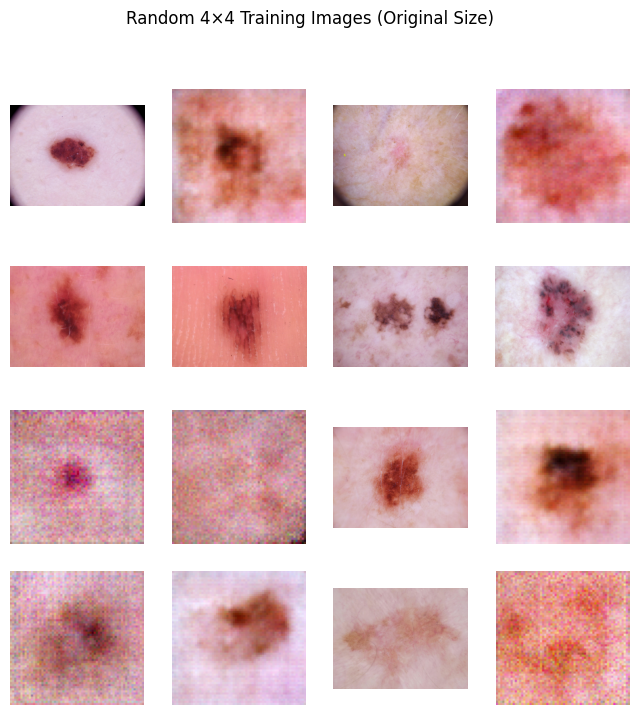

In [ ]:
# sample 16 images
sample_images = random.sample(image_paths, 16)

# plot 4×4
plt.figure(figsize=(8,8))
for i, img_path in enumerate(sample_images):
    img = Image.open(img_path).convert("RGB")
    plt.subplot(4,4,i+1)
    plt.imshow(img)
    plt.axis("off")
plt.suptitle("Random 4×4 Training Images (Original Size)", fontsize=12)
plt.show()

## Prepare Data for the CNN

- Resize the data into 224x224 and apply basic image transformations.
- Load the datasets and use PyTorch data loaders to handle batching and shuffling.

In [6]:

train_transform = transforms.Compose([
    transforms.Resize((224,224)),   # RESIZE
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((224,224)),  # RESIZE
    transforms.ToTensor()
])

- The dataset is organized using `torchvision.datasets.ImageFolder`.
- Separate folders are created for train, validation, and test sets

In [9]:

train_ds = datasets.ImageFolder(data_root+"/train", transform=train_transform)
val_ds   = datasets.ImageFolder(data_root+"/val", transform=val_transform)
test_ds  = datasets.ImageFolder(data_root+"/test", transform=val_transform)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=32)
test_loader  = DataLoader(test_ds, batch_size=32)

num_classes = len(train_ds.classes)
print("Classes:", train_ds.classes)

Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


## Build the Model

- Input
  - Shape: (batch, 3, 224, 224) RGB images
  - After 4 max-pool layers -> spatial size becomes 14×14
- Convolutional blocks
  - Conv(3->32) -> ReLU -> MaxPool (224 -> 112)
  - Conv(32->64) -> ReLU -> MaxPool (112 -> 56)
  - Conv(64->128) -> ReLU -> MaxPool (56 -> 28)
  - Conv(128->256) -> ReLU -> MaxPool (28 -> 14)
- Output
  - Shape: (batch, num_classes)
  

- Regularization Techniques:
  - Dropout applied.
    Values tested: 0.0, 0.2, 0.5, 0.7
  - Data augmentation (flip, rotation)
  - Validation split used for early error detection

In [35]:
class SkinCNN(nn.Module):
    def __init__(self, num_classes, dropout=0.0):
        super().__init__()
        # Layer 1: input 3 channels (RGB) -> 32
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        # Layer 2: 32 -> 64
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        # MaxPool: 224 -> 112
        self.pool = nn.MaxPool2d(2,2)
        # Layer 3: 64 -> 128
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        # Layer 4: 128 -> 256
        self.conv4 = nn.Conv2d(128, 256, 3, padding=1)
        self.dropout = nn.Dropout(dropout)
        # flattened features
        self.fc1 = nn.Linear(256*14*14, 512)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):

        # convolution + ReLU + max-pooling
        x = self.pool(F.relu(self.conv1(x)))   # -> (B, 32, 112, 112)
        x = self.pool(F.relu(self.conv2(x)))   # -> (B, 64, 56, 56)
        x = self.pool(F.relu(self.conv3(x)))   # -> (B, 128, 28, 28)
        x = self.pool(F.relu(self.conv4(x)))   # -> (B, 256, 14, 14)

        #Flatten feature maps
        x = x.view(x.size(0), -1)
        # Fully connected layer + ReLU
        x = F.relu(self.fc1(x))

        #Dropout for regularization
        x = self.dropout(x)
        return self.fc2(x)

## Define Optimizer Function

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
lr = 1e-4
dropout = 0.0
num_epochs = 20

# build and move model to device
model = SkinCNN(num_classes)
model = model.to(device)

# create optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
criterion = torch.nn.CrossEntropyLoss()

## Train the Data

In [17]:
# train one epoch and eval on val
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()*imgs.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds==labels).sum().item()
        total += labels.size(0)
    return running_loss/total, correct/total

def eval_model(model, loader, criterion):
    model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss_sum += loss.item()*imgs.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds==labels).sum().item()
            total += labels.size(0)
    return loss_sum/total, correct/total


- Train for 20 epochs and evaluate on val set.

In [ ]:
train_loss_hist, val_loss_hist = [], []
train_acc_hist, val_acc_hist = [], []

for epoch in range(1, num_epochs+1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = eval_model(model, val_loader, criterion)

    train_loss_hist.append(tr_loss); val_loss_hist.append(val_loss)
    train_acc_hist.append(tr_acc);  val_acc_hist.append(val_acc)

    print(f"Epoch [{epoch}/{num_epochs}] TrainLoss: {tr_loss:.4f} "
          f"TrainAcc: {tr_acc:.4f} ValLoss: {val_loss:.4f} ValAcc: {val_acc:.4f}", flush=True)



Epoch [1/20] TrainLoss: 1.1539 TrainAcc: 0.5837 ValLoss: 0.9821 ValAcc: 0.6443
Epoch [2/20] TrainLoss: 0.5951 TrainAcc: 0.7922 ValLoss: 0.8020 ValAcc: 0.7114
Epoch [3/20] TrainLoss: 0.4915 TrainAcc: 0.8241 ValLoss: 0.7560 ValAcc: 0.7134
Epoch [4/20] TrainLoss: 0.4452 TrainAcc: 0.8410 ValLoss: 0.7408 ValAcc: 0.7367
Epoch [5/20] TrainLoss: 0.4206 TrainAcc: 0.8470 ValLoss: 0.7412 ValAcc: 0.7213
Epoch [6/20] TrainLoss: 0.4081 TrainAcc: 0.8530 ValLoss: 0.7174 ValAcc: 0.7288
Epoch [7/20] TrainLoss: 0.3920 TrainAcc: 0.8598 ValLoss: 0.6973 ValAcc: 0.7442
Epoch [8/20] TrainLoss: 0.3817 TrainAcc: 0.8616 ValLoss: 0.7276 ValAcc: 0.7322
Epoch [9/20] TrainLoss: 0.3710 TrainAcc: 0.8653 ValLoss: 0.6702 ValAcc: 0.7496
Epoch [10/20] TrainLoss: 0.3552 TrainAcc: 0.8673 ValLoss: 0.6998 ValAcc: 0.7367
Epoch [11/20] TrainLoss: 0.3490 TrainAcc: 0.8690 ValLoss: 0.6578 ValAcc: 0.7561
Epoch [12/20] TrainLoss: 0.3382 TrainAcc: 0.8715 ValLoss: 0.6829 ValAcc: 0.7447
Epoch [13/20] TrainLoss: 0.3270 TrainAcc: 0.8773 

## Plot Training and Validation Curves

In [ ]:
def plot_loss(train_loss, val_loss, log_scale=False):
    plt.figure(figsize=(8,5))
    plt.plot(train_loss, color="blue", linestyle="-", label="train")
    plt.plot(val_loss, color="red", linestyle="--", label="val")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid(True, which="both", ls=":")

    if log_scale:
        plt.yscale("log")
        plt.ylabel("Loss (log scale)")

    plt.show()

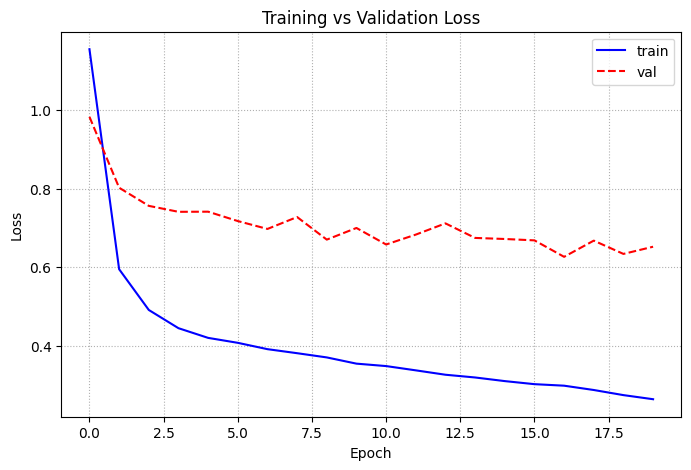

In [ ]:
# Plot
plot_loss(train_loss_hist, val_loss_hist)


## Hyperparameter Search: Learning Rate vs Dropout

- Learning Rate:  1e-4, 1e-3
- Dropout:  0.0, 0.2, 0.5, 0.7
- Batch Size: 32
- Epochs: 20

In [ ]:
# Hyperparameters
lrs = [1e-4, 1e-3]
dropouts = [0.2, 0.5, 0.7]
num_epochs = 20
best = {"val_acc": -1.0}
results = []

In [ ]:

for lr in lrs:
    for dp in dropouts:

        # model for each combination
        model_hp = SkinCNN(num_classes, dropout=dp).to(device)

        optimizer_hp = torch.optim.Adam(model_hp.parameters(), lr=lr)
        criterion_hp = torch.nn.CrossEntropyLoss()

        train_acc_final = 0.0
        val_acc_final   = 0.0

        for epoch in range(1, num_epochs+1):

            train_loss, train_acc = train_one_epoch(model_hp, train_loader, optimizer_hp, criterion_hp)
            val_loss, val_acc     = eval_model(model_hp, val_loader, criterion_hp)
            train_acc_final = train_acc
            val_acc_final   = val_acc



        print(f"\nTraining with lr={lr}, dropout={dp}")
        print(f"train_acc={train_acc_final:.3f}, val_acc={val_acc_final:.3f}\n")

        # store results
        results.append({
            "lr": lr,
            "dropout": dp,
            "train_acc": train_acc_final,
            "val_acc": val_acc_final
        })

        # update best Values
        if val_acc_final > best["val_acc"]:
            best = {
                "lr": lr,
                "dropout": dp,
                "val_acc": val_acc_final,
                "train_acc": train_acc_final
            }



Training with lr=0.0001, dropout=0.2
train_acc=0.898, val_acc=0.749


Training with lr=0.0001, dropout=0.5
train_acc=0.889, val_acc=0.753


Training with lr=0.0001, dropout=0.7
train_acc=0.864, val_acc=0.767


Training with lr=0.001, dropout=0.2
train_acc=0.922, val_acc=0.736


Training with lr=0.001, dropout=0.5
train_acc=0.898, val_acc=0.734


Training with lr=0.001, dropout=0.7
train_acc=0.872, val_acc=0.746



## Train Final Model

- Choosing the best learning rate:0.0001
and dropout: 0.7

In [20]:
final_lr = 0.0001
final_dp = 0.7
num_epochs=20

In [21]:
model = SkinCNN(num_classes, dropout=final_dp).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=final_lr)
criterion = torch.nn.CrossEntropyLoss()

train_loss_history = []
train_acc_history = []
val_loss_history = []
val_acc_history = []

for epoch in range(1, num_epochs+1):
    t_loss, t_acc = train_one_epoch(model, train_loader, optimizer, criterion)
    v_loss, v_acc = eval_model(model, val_loader, criterion)

    train_loss_history.append(t_loss)
    train_acc_history.append(t_acc)
    val_loss_history.append(v_loss)
    val_acc_history.append(v_acc)

    print(f"[Epoch {epoch}/{num_epochs}] "
          f"train_loss={t_loss:.4f} train_acc={t_acc:.4f}  "
          f"val_loss={v_loss:.4f} val_acc={v_acc:.4f}")


[Epoch 1/20] train_loss=1.3222 train_acc=0.4914  val_loss=0.9844 val_acc=0.6384
[Epoch 2/20] train_loss=0.8831 train_acc=0.6886  val_loss=0.8842 val_acc=0.6587
[Epoch 3/20] train_loss=0.6725 train_acc=0.7659  val_loss=0.7926 val_acc=0.6935
[Epoch 4/20] train_loss=0.5765 train_acc=0.7997  val_loss=0.8119 val_acc=0.6975
[Epoch 5/20] train_loss=0.5327 train_acc=0.8096  val_loss=0.7267 val_acc=0.7218
[Epoch 6/20] train_loss=0.4892 train_acc=0.8261  val_loss=0.7772 val_acc=0.7124
[Epoch 7/20] train_loss=0.4700 train_acc=0.8329  val_loss=0.7225 val_acc=0.7263
[Epoch 8/20] train_loss=0.4500 train_acc=0.8398  val_loss=0.6824 val_acc=0.7501
[Epoch 9/20] train_loss=0.4349 train_acc=0.8404  val_loss=0.6991 val_acc=0.7462
[Epoch 10/20] train_loss=0.4237 train_acc=0.8467  val_loss=0.7224 val_acc=0.7362
[Epoch 11/20] train_loss=0.4199 train_acc=0.8477  val_loss=0.6520 val_acc=0.7551
[Epoch 12/20] train_loss=0.4073 train_acc=0.8528  val_loss=0.6580 val_acc=0.7546
[Epoch 13/20] train_loss=0.3954 train

In [30]:
# Save the final model
torch.save(model.state_dict(), "final_model.pth")
print("\nFinal model saved as final_model.pth")



Final model saved as final_model.pth


 ## Plot Loss Cureve

In [26]:
def plot_loss(train_loss, val_loss, log_scale=False):
    plt.figure(figsize=(8,5))
    plt.plot(train_loss, color="blue", linestyle="-", label="train")
    plt.plot(val_loss, color="red", linestyle="--", label="val")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid(True, which="both", ls=":")

    if log_scale:
        plt.yscale("log")
        plt.ylabel("Loss (log scale)")

    plt.show()

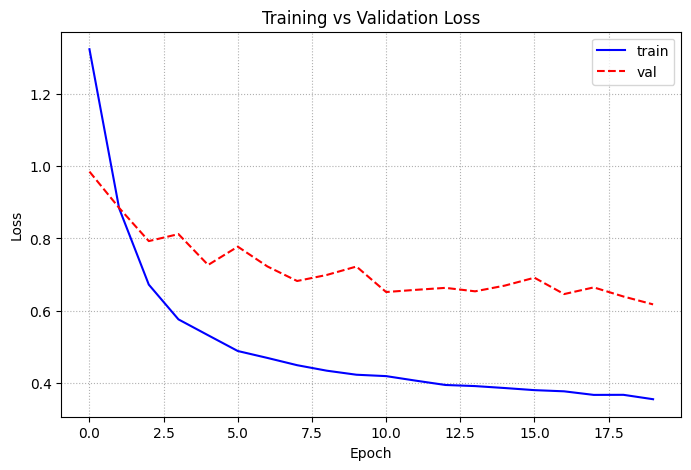

In [28]:
# Plot
plot_loss(train_loss_history, val_loss_history)

## Predict the Test

In [31]:
model.load_state_dict(torch.load("final_model.pth", map_location=device))
model.to(device)
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        preds = outputs.argmax(dim=1).cpu().numpy()
        y_pred.extend(preds)
        y_true.extend(labels.numpy())

## Classification Report and Confusion Matrix

The model was evaluated using accuracy, Precision, Recall, F1-score, Confusion matrix


Classification Report:
              precision    recall  f1-score   support

       akiec     0.6250    0.3030    0.4082        33
         bcc     0.5781    0.7255    0.6435        51
         bkl     0.6133    0.4220    0.5000       109
          df     0.3333    0.0909    0.1429        11
         mel     0.5797    0.3636    0.4469       110
          nv     0.8355    0.9488    0.8886       664
        vasc     0.9091    0.7143    0.8000        14

    accuracy                         0.7802       992
   macro avg     0.6392    0.5097    0.5471       992
weighted avg     0.7580    0.7802    0.7588       992



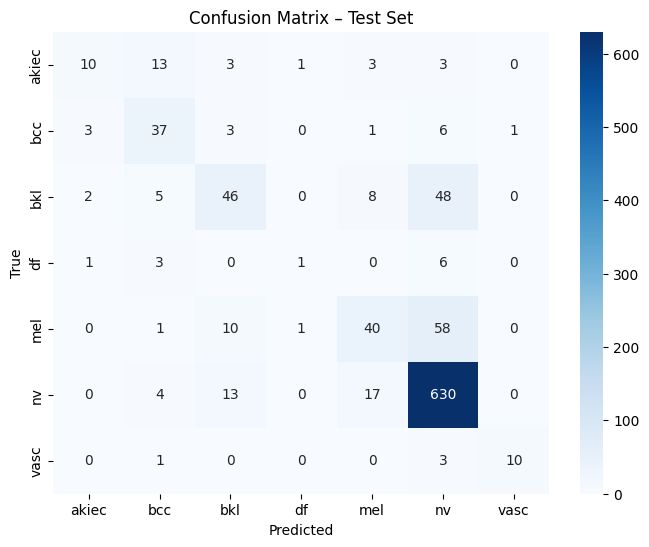

In [34]:
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=train_ds.classes, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=train_ds.classes,
            yticklabels=train_ds.classes,
            cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix – Test Set")
plt.show()

Effective feature learning is demonstrated by the model's good overall performance, especially on well-represented classes like nv and vasc. However, because of the extreme class imbalance and visual resemblance across lesions, it frequently misclassifies minority classes like mel, df, and akiec as nv. These flaws show that there is little generalization for uncommon and clinically significant categories. Applying class-balanced loss functions (such as weighted loss or focal loss), expanding training samples for minority classes via GAN augmentation or oversampling, and utilizing transfer learning models like ResNet or EfficientNet to more accurately capture minute dermoscopic patterns can all enhance model performance.